In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("powerplant_data.csv")

In [3]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [4]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [5]:
X = df.drop("PE", axis=1)
y = df["PE"]

In [6]:
# Step -2

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [8]:
df.shape

(9568, 5)

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [10]:
X_test_scaled

array([[ 1.34499288,  0.23869298, -1.28658067, -1.10532538],
       [ 0.81095912,  1.36269098, -0.74140656,  0.26485915],
       [-0.2437241 , -0.73900436,  1.99970178, -0.19713193],
       ...,
       [-0.67068342, -1.15902881, -0.29951077, -0.10651852],
       [ 1.31420898,  1.33752097, -0.87346737, -0.44288647],
       [-0.2611237 , -0.27021304,  0.37433797,  1.10646548]],
      shape=(1914, 4))

In [17]:
import torch
import torch.nn as nn

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1,1)   #not in numpy arr

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1,1)   #not in numpy arr


In [18]:
type(y_train)
y_train.shape   #(n,) but (n,1)

(7654,)

In [19]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

In [20]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

# Deep Learning

In [41]:
# ANN = 
# class <== nn.Module (Base class)

class ANN(nn.Module) :
    def __init__(self):
        super(ANN, self).__init__()

        # ANN model -
        self.model = nn.Sequential(
            # 1st hidden-
            nn.Linear(X_train.shape[1], 6),
            nn.ReLU(),
    
            #2nd hidden-
            nn.Linear(6,6),
            nn.ReLU(),
    
            # output layer-
            nn.Linear(6,1),
        )

    def forward(self, x):
        return self.model(x)

In [42]:
# loss , optimizer
import torch.optim as optim

model = ANN()

crietrion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

# Training model -

In [43]:

train_losses = []
valid_losses = []

best_val_loss = float("inf")
epochs = 100

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for xb, yb in train_loader:
        # xb = feature of 1 batch
        # yb = laels of 1 batch
        optimizer.zero_grad()
        
        outputs = model(xb)       # forward prop....predicted output
        loss = crietrion(outputs, yb)    # compute loss
        loss.backward()           # back prop... compute gradients
        optimizer.step()          # params update

        running_loss += loss.item()  # loss tensor -> py float

    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)


    # validation - 
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for xb, yb in test_loader:
            outputs = model(xb)       # forward prop....predicted output
            loss = crietrion(outputs, yb)    # compute loss
            running_val_loss += loss

    epoch_val_loss = running_val_loss / len(test_loader)
    valid_losses.append(epoch_val_loss)

    print(f"epoch ${epoch+1}/{epochs} ==> train loss = ${epoch_train_loss} & val loss = ${epoch_val_loss}")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt")
        

epoch $1/100 ==> train loss = $206891.02154947916 & val loss = $206418.109375
epoch $2/100 ==> train loss = $202702.0521484375 & val loss = $194317.015625
epoch $3/100 ==> train loss = $177520.15885416666 & val loss = $155678.78125
epoch $4/100 ==> train loss = $128933.64931640626 & val loss = $101185.796875
epoch $5/100 ==> train loss = $81043.47049153646 & val loss = $62054.33984375
epoch $6/100 ==> train loss = $48486.087662760416 & val loss = $34570.6796875
epoch $7/100 ==> train loss = $26130.75686035156 & val loss = $17935.31640625
epoch $8/100 ==> train loss = $14347.652211507162 & val loss = $11057.3720703125
epoch $9/100 ==> train loss = $9438.294012451172 & val loss = $7896.458984375
epoch $10/100 ==> train loss = $6822.81142578125 & val loss = $5847.04248046875
epoch $11/100 ==> train loss = $5025.881964111328 & val loss = $4335.18408203125
epoch $12/100 ==> train loss = $3732.396248881022 & val loss = $3246.530029296875
epoch $13/100 ==> train loss = $2843.0050674438476 & v

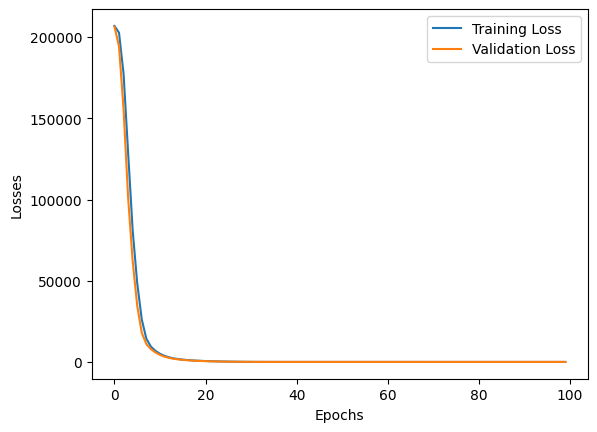

In [44]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss" : train_losses,
    "Validation Loss" : valid_losses
})

plt.plot(loss_df["Training Loss"], label = "Training Loss")
plt.plot(loss_df["Validation Loss"], label = "Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [45]:
# Loading best model 

model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [47]:
# Evaluation -

model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = crietrion(train_preds, y_train_tensor)
    test_mse_loss = crietrion(test_preds, y_test_tensor)

print("Training MSE: ", train_mse_loss.item())
print("Testing MSE: ", test_mse_loss.item())

Training MSE:  20.321027755737305
Testing MSE:  18.637948989868164


In [48]:
from sklearn.metrics import r2_score

print(r2_score(y_test, test_preds))

0.9348651765628835


In [50]:
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values, columns=["Actual Values"])

pd.concat([predicted_df, actual_df], axis=1)

,Predicted Values,Actual Values
0,435.519501,433.27
1,437.015594,438.16
2,461.097595,458.42
3,475.937531,480.82
4,435.375519,441.41
...,...,...
1909,451.396912,456.70
1910,431.811554,438.04
1911,467.633057,467.80
1912,431.222198,437.14
